In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import os
from pathlib import Path

In [5]:
# Load metadata
df = pd.read_csv('../data/raw/ISIC_2019_Training_GroundTruth.csv')

In [6]:
# Display basic info
print(f"Total images: {len(df)}")
print(f"\nClass distribution:")
print(df.iloc[:, 1:].sum().sort_values(ascending=False))

Total images: 25331

Class distribution:
NV      12875.0
MEL      4522.0
BCC      3323.0
BKL      2624.0
AK        867.0
SCC       628.0
VASC      253.0
DF        239.0
UNK         0.0
dtype: float64


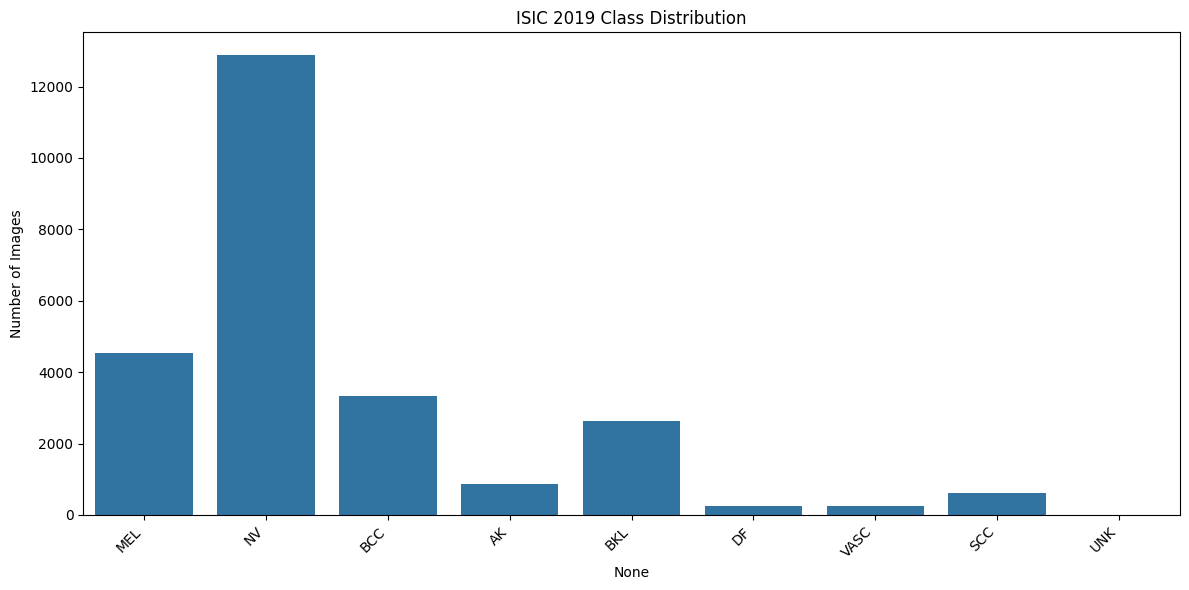

In [16]:
# Visualize class distribution
class_counts = df.iloc[:, 1:].sum()
plt.figure(figsize=(12, 6))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.xticks(rotation=45, ha='right')
plt.title('ISIC 2019 Class Distribution')
plt.ylabel('Number of Images')
plt.tight_layout()
plt.savefig('../results/figures/class_distribution.png', dpi=300)
plt.show()

In [10]:
# Analyze image dimensions
image_dir = Path('../data/raw/ISIC_2019_Training_Input')
sample_size = 1000
widths, heights = [], []

for i, img_name in enumerate(df['image'].head(sample_size)):
    img_path = image_dir / f"{img_name}.jpg"
    if img_path.exists():
        img = Image.open(img_path)
        widths.append(img.width)
        heights.append(img.height)

print(f"\nImage dimensions (from {sample_size} samples):")
print(f"Width  - Min: {min(widths)}, Max: {max(widths)}, Mean: {np.mean(widths):.0f}")
print(f"Height - Min: {min(heights)}, Max: {max(heights)}, Mean: {np.mean(heights):.0f}")


Image dimensions (from 1000 samples):
Width  - Min: 576, Max: 1024, Mean: 987
Height - Min: 540, Max: 1024, Mean: 732


⚠️ No samples for 'UNK'. Skipping.


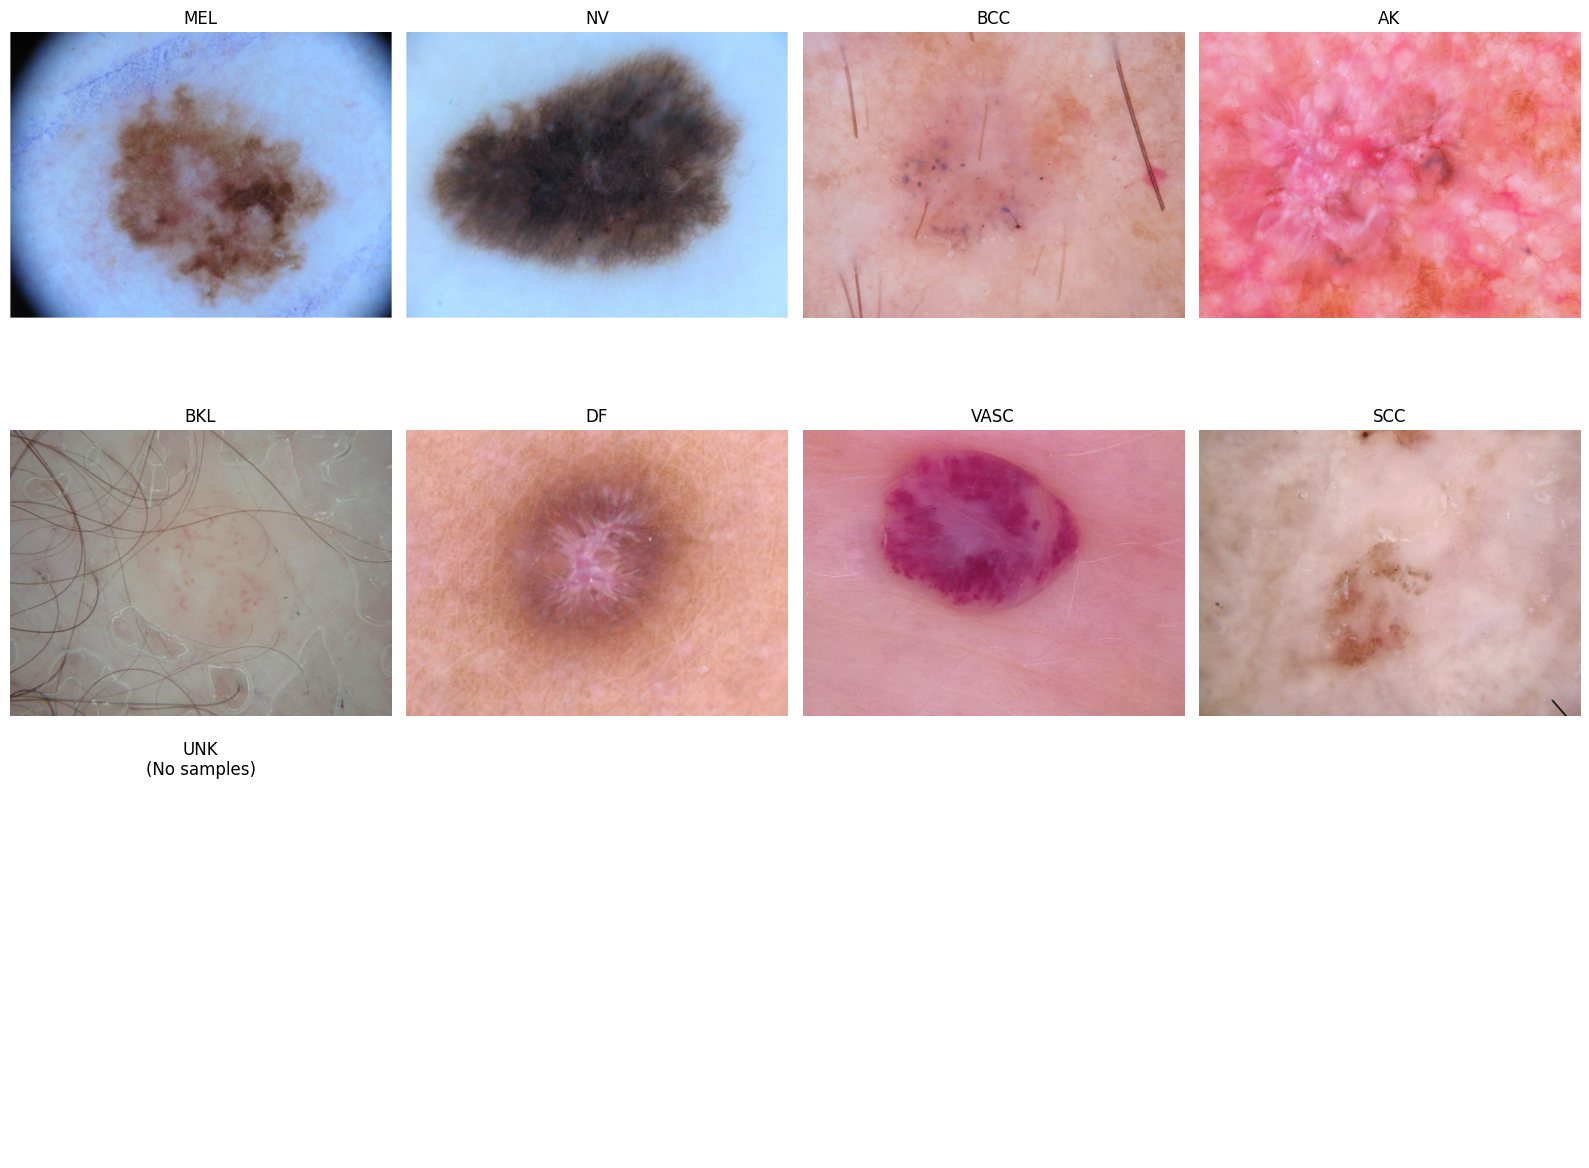

In [ ]:
import math

class_names = df.columns[1:]              
num_classes = len(class_names)

rows = math.ceil(num_classes / 4)         
cols = 4

fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
axes = axes.ravel()

for idx, class_name in enumerate(class_names):
    class_samples = df[df[class_name] == 1]

    if class_samples.empty:
        print(f"No samples for '{class_name}'. Skipping.")
        axes[idx].set_title(f"{class_name}\n(No samples)")
        axes[idx].axis('off')
        continue

    sample_img = class_samples.iloc[0]['image']
    img_path = image_dir / f"{sample_img}.jpg"

    try:
        img = Image.open(img_path)
        axes[idx].imshow(img)
        axes[idx].set_title(class_name)
        axes[idx].axis('off')
    except FileNotFoundError:
        print(f"Missing image: {img_path}")
        axes[idx].set_title(f"{class_name}\n(Missing image)")
        axes[idx].axis('off')

# Turn off extra blank subplots
for j in range(idx+1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.savefig('../results/figures/sample_images_per_class.png', dpi=300)
plt.show()
